<a href="https://colab.research.google.com/github/natsakh/ElectromagneticNets/blob/main/TimeVaryingMedia/PINNs/InitialValueProblems/AnalyticalBenchmarks/5_temporal_slab_wave_splitting_benchmark.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Temporal Slab: Wave Splitting and Frequency Conversion

This notebook reproduces the temporal-slab experiment and Figure 5 from
*Physics-Informed Neural Networks for Electromagnetic Wave Propagation in
Time-Varying Media: Analytical Benchmarks for Initial-Value Problems*.

The medium changes from $n_1=1.5$ to $n_2=1.8$ at $t=0$ and returns to
$n_1$ at $t=5T_0$. The global SIREN PINN is trained on $0\le t\le20T_0$.
After training, the predicted $D$ and $B$ fields are decomposed into temporal
forward and backward components, their frequencies are extracted from the
unwrapped phases, and Figure 5 is generated.


In [ ]:
from pathlib import Path
import csv
import json
import time
import random
import math

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from datetime import datetime

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)

from google.colab import drive
drive.mount("/content/drive")

timestamp = datetime.now().strftime("%Y%m%d_%H%M")
EXPERIMENT = f"temporal_slab_wave_splitting_{timestamp}"

BASE_DIR = Path("/content/drive/MyDrive/TimeVaryingMedia")
OUTPUT_DIR = BASE_DIR / EXPERIMENT
MODELS_DIR = OUTPUT_DIR / "models"
LOSS_DIR = OUTPUT_DIR / "loss_history"
PREDICTIONS_DIR = OUTPUT_DIR / "predictions"
FIGURES_DIR = OUTPUT_DIR / "figures"

for directory in [OUTPUT_DIR, MODELS_DIR, LOSS_DIR, PREDICTIONS_DIR, FIGURES_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

print("Saving to:", OUTPUT_DIR)


## Physical parameters

The second temporal interface returns the medium to the initial refractive
index, \(n_2\rightarrow n_1\), so this is a true temporal slab.

In [ ]:
# Physical parameters
n1 = 1.5
n2 = 1.8
omega1 = 2 * np.pi
E0 = 1.0

epsilon0 = 1.0
mu0 = 1.0
c = 1.0

T0 = 2 * np.pi / omega1
k1 = n1 * omega1 / c
omega2 = k1 / (n2 * np.sqrt(mu0 * epsilon0))

D0 = epsilon0 * n1**2 * E0
H0 = n1 / (mu0 * c) * E0
B0 = mu0 * H0


## Experiment configuration

The temporal slab has duration $T_{\rm slab}=5T_0$ and the observation window
extends to $20T_0$. The network and optimizer settings follow Table 1, with
the tanh activation and initialization replaced by SIREN as described in the
paper. One representative run is used for this physics-demonstration figure.


In [ ]:
# ============================================================
# USER CONFIGURATION
# ============================================================
MODULATION = "temporal_slab"
METHOD = "global_siren"

SEED = 42
SLAB_DURATION = 5.0        # T_slab / T0
TAU_MAX = 20.0              # final observation time / T0

# ============================================================
# FIXED SETTINGS
# ============================================================
N_COLLOCATION_PER_PERIOD = 500
N_EVAL_PER_PERIOD = 500

ADAM_EPOCHS = 10000
ADAM_LEARNING_RATE = 1e-3

LBFGS_MAX_ITER = 1000
LBFGS_HISTORY_SIZE = 100
LBFGS_TOLERANCE_GRAD = 1e-9
LBFGS_TOLERANCE_CHANGE = 1e-12
LBFGS_LINE_SEARCH_FN = "strong_wolfe"

IC_WEIGHT = 20.0
GRAD_CLIP = 1.0

HIDDEN_LAYERS = 4
HIDDEN_DIM = 64
ARCHITECTURE = f"{HIDDEN_LAYERS}x{HIDDEN_DIM}"

# Known incident frequency only; no shifted frequency is supplied.
SIREN_OMEGA = omega1

if SLAB_DURATION <= 0:
    raise ValueError("SLAB_DURATION must be positive.")
if TAU_MAX <= SLAB_DURATION:
    raise ValueError("TAU_MAX must extend beyond the second temporal interface.")

CONFIG = {
    "benchmark": MODULATION,
    "method": METHOD,
    "seed": SEED,
    "slab_duration": SLAB_DURATION,
    "tau_max": TAU_MAX,
    "n_collocation_per_period": N_COLLOCATION_PER_PERIOD,
    "n_eval_per_period": N_EVAL_PER_PERIOD,
    "adam_epochs": ADAM_EPOCHS,
    "adam_learning_rate": ADAM_LEARNING_RATE,
    "lbfgs_max_iter": LBFGS_MAX_ITER,
    "lbfgs_history_size": LBFGS_HISTORY_SIZE,
    "lbfgs_tolerance_grad": LBFGS_TOLERANCE_GRAD,
    "lbfgs_tolerance_change": LBFGS_TOLERANCE_CHANGE,
    "lbfgs_line_search_fn": LBFGS_LINE_SEARCH_FN,
    "ic_weight": IC_WEIGHT,
    "grad_clip": GRAD_CLIP,
    "optimizer": "Adam + L-BFGS",
    "architecture": ARCHITECTURE,
    "hidden_layers": HIDDEN_LAYERS,
    "hidden_dim": HIDDEN_DIM,
    "siren_omega": float(SIREN_OMEGA),
    "siren_omega_source": "incident frequency omega1",
    "physical_parameters": {
        "n1": float(n1),
        "n2": float(n2),
        "omega1": float(omega1),
        "omega2": float(omega2),
        "E0": float(E0),
        "epsilon0": float(epsilon0),
        "mu0": float(mu0),
        "c": float(c),
        "T0": float(T0),
        "k1": float(k1),
        "D0": float(D0),
        "B0": float(B0),
    },
}

with (OUTPUT_DIR / "config.json").open("w", encoding="utf-8") as f:
    json.dump(CONFIG, f, indent=2)

print(json.dumps(CONFIG, indent=2))


## Reproducibility

In [ ]:
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


## SIREN PINN architecture

The network input is normalized time \(t/T_{\rm ref}\). The four outputs are
\(\Re D,\Im D,\Re B,\Im B\).

In [ ]:
class SineLayer(nn.Module):
    def __init__(self, in_features, out_features, omega_0, is_first=False):
        super().__init__()
        self.in_features = in_features
        self.omega_0 = float(omega_0)
        self.linear = nn.Linear(in_features, out_features)
        self.reset_parameters(is_first)

    def reset_parameters(self, is_first):
        with torch.no_grad():
            if is_first:
                bound = 1.0 / self.in_features
            else:
                bound = math.sqrt(6.0 / self.in_features) / self.omega_0
            self.linear.weight.uniform_(-bound, bound)
            self.linear.bias.uniform_(-bound, bound)

    def forward(self, x):
        return torch.sin(self.omega_0 * self.linear(x))


class SirenPINN(nn.Module):
    def __init__(self, hidden_dim=64, hidden_layers=4, omega_0=2*np.pi):
        super().__init__()
        layers = [SineLayer(1, hidden_dim, omega_0, is_first=True)]
        for _ in range(hidden_layers - 1):
            layers.append(SineLayer(hidden_dim, hidden_dim, omega_0, is_first=False))
        self.hidden = nn.Sequential(*layers)
        self.output = nn.Linear(hidden_dim, 4)

        with torch.no_grad():
            bound = math.sqrt(6.0 / hidden_dim) / float(omega_0)
            self.output.weight.uniform_(-bound, bound)
            self.output.bias.uniform_(-bound, bound)

    def forward(self, t):
        return self.output(self.hidden(t))


def build_model():
    return SirenPINN(HIDDEN_DIM, HIDDEN_LAYERS, SIREN_OMEGA)


## Maxwell residuals and initial-condition loss

In [ ]:
def gradients(y, x):
    return torch.autograd.grad(
        y, x, torch.ones_like(y), create_graph=True
    )[0]


def refractive_index_torch(t):
    # The first jump n1 -> n2 occurs at t=0.
    # The PINN domain is t>=0, so only n2 and the return to n1 appear here.
    return torch.where(
        t < SLAB_DURATION,
        torch.full_like(t, n2),
        torch.full_like(t, n1),
    )


def physics_loss(model, t):
    fields = model(t)
    dR, dI = fields[:, 0:1], fields[:, 1:2]
    bR, bI = fields[:, 2:3], fields[:, 3:4]

    dR_t, dI_t = gradients(dR, t), gradients(dI, t)
    bR_t, bI_t = gradients(bR, t), gradients(bI, t)

    n_t = refractive_index_torch(t)

    residual_dR = dR_t + k1 / mu0 * bI
    residual_dI = dI_t - k1 / mu0 * bR
    residual_bR = bR_t + k1 / (epsilon0 * n_t**2) * dI
    residual_bI = bI_t - k1 / (epsilon0 * n_t**2) * dR

    return torch.mean(
        residual_dR**2 + residual_dI**2
        + residual_bR**2 + residual_bI**2
    )


def initial_loss(model, t0):
    fields0 = model(t0)
    target = torch.tensor(
        [[D0, 0.0, B0, 0.0]],
        dtype=torch.float32,
        device=device,
    )
    return torch.mean((fields0 - target)**2)


## Training utilities

In [ ]:
def make_training_tensors(seed):
    set_seed(seed)
    n_f = max(1, int(N_COLLOCATION_PER_PERIOD * TAU_MAX))
    tau_f_np = np.random.rand(n_f, 1) * TAU_MAX
    tau_f = torch.tensor(
        tau_f_np, dtype=torch.float32, device=device, requires_grad=True
    )
    tau0 = torch.tensor(
        [[0.0]], dtype=torch.float32, device=device, requires_grad=True
    )
    return tau_f, tau0


def evaluate_losses(model, tau_f, tau0):
    n_eval = int(N_EVAL_PER_PERIOD * TAU_MAX) + 1
    tau_val = torch.linspace(0.0, TAU_MAX, n_eval, device=device).reshape(-1, 1)
    tau_val.requires_grad_(True)

    phys_train = physics_loss(model, tau_f)
    phys_eval = physics_loss(model, tau_val)
    ic = initial_loss(model, tau0)

    return {
        "total_loss": (phys_train + IC_WEIGHT * ic).item(),
        "physics_train_loss": phys_train.item(),
        "physics_eval_loss": phys_eval.item(),
        "initial_loss": ic.item(),
    }


def train_adam(model, tau_f, tau0):
    optimizer = torch.optim.Adam(model.parameters(), lr=ADAM_LEARNING_RATE)
    history = []
    training_time_s = 0.0

    for epoch in range(ADAM_EPOCHS):
        if torch.cuda.is_available():
            torch.cuda.synchronize()
        start = time.perf_counter()

        optimizer.zero_grad()
        phys = physics_loss(model, tau_f)
        ic = initial_loss(model, tau0)
        total = phys + IC_WEIGHT * ic

        total.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)
        optimizer.step()

        if torch.cuda.is_available():
            torch.cuda.synchronize()
        training_time_s += time.perf_counter() - start

        history.append({
            "stage": "Adam",
            "step": epoch + 1,
            "adam_epoch": epoch + 1,
            "lbfgs_iteration": 0,
            "function_evaluation": 0,
            "total_loss": total.item(),
            "physics_train_loss": phys.item(),
            "physics_eval_loss": np.nan,
            "initial_loss": ic.item(),
        })

    history.append({
        "stage": "Adam final",
        "step": ADAM_EPOCHS,
        "adam_epoch": ADAM_EPOCHS,
        "lbfgs_iteration": 0,
        "function_evaluation": 0,
        **evaluate_losses(model, tau_f, tau0),
    })
    return history, training_time_s


def train_lbfgs(model, tau_f, tau0):
    optimizer = torch.optim.LBFGS(
        model.parameters(),
        max_iter=LBFGS_MAX_ITER,
        history_size=LBFGS_HISTORY_SIZE,
        tolerance_grad=LBFGS_TOLERANCE_GRAD,
        tolerance_change=LBFGS_TOLERANCE_CHANGE,
        line_search_fn=LBFGS_LINE_SEARCH_FN,
    )

    raw_history = []
    function_evaluations = 0

    def closure():
        nonlocal function_evaluations
        optimizer.zero_grad()
        phys = physics_loss(model, tau_f)
        ic = initial_loss(model, tau0)
        total = phys + IC_WEIGHT * ic
        total.backward()

        function_evaluations += 1
        raw_history.append(
            (function_evaluations, total.detach(), phys.detach(), ic.detach())
        )
        return total

    if torch.cuda.is_available():
        torch.cuda.synchronize()
    start = time.perf_counter()

    optimizer.step(closure)

    if torch.cuda.is_available():
        torch.cuda.synchronize()
    training_time_s = time.perf_counter() - start

    state = optimizer.state.get(optimizer._params[0], {})
    iterations = int(state.get("n_iter", 0))
    func_evals = int(state.get("func_evals", function_evaluations))

    history = [{
        "stage": "L-BFGS",
        "step": fe,
        "adam_epoch": ADAM_EPOCHS,
        "lbfgs_iteration": np.nan,
        "function_evaluation": fe,
        "total_loss": total.item(),
        "physics_train_loss": phys.item(),
        "physics_eval_loss": np.nan,
        "initial_loss": ic.item(),
    } for fe, total, phys, ic in raw_history]

    history.append({
        "stage": "L-BFGS final",
        "step": function_evaluations + 1,
        "adam_epoch": ADAM_EPOCHS,
        "lbfgs_iteration": iterations,
        "function_evaluation": func_evals,
        **evaluate_losses(model, tau_f, tau0),
    })
    return history, training_time_s, iterations, func_evals


## Analytical reference solution

The analytical solution is propagated through the constant-index slab $n_2$
and then through the restored medium $n_1$. Both $D$ and $B$ remain continuous
at the two temporal interfaces. The analytical fields are used only for
evaluation and Figure 5.


In [ ]:
def propagate_constant_index(D_start, B_start, dt, n):
    omega = k1 / (n * np.sqrt(mu0 * epsilon0))
    phase = omega * dt

    D = (
        D_start * np.cos(phase)
        + 1j * k1 / (mu0 * omega) * B_start * np.sin(phase)
    )
    B = (
        B_start * np.cos(phase)
        + 1j * k1 / (epsilon0 * n**2 * omega) * D_start * np.sin(phase)
    )
    return D, B


def exact_fields(tau):
    tau = np.asarray(tau, dtype=float)
    d_true = np.empty(tau.shape, dtype=complex)
    b_true = np.empty(tau.shape, dtype=complex)

    inside = tau < SLAB_DURATION
    after = tau >= SLAB_DURATION

    if np.any(inside):
        d_true[inside], b_true[inside] = propagate_constant_index(
            D0, B0, tau[inside], n2
        )

    D2, B2 = propagate_constant_index(D0, B0, SLAB_DURATION, n2)

    if np.any(after):
        d_true[after], b_true[after] = propagate_constant_index(
            D2, B2, tau[after] - SLAB_DURATION, n1
        )

    return d_true, b_true


# Basic checks
D_at_0, B_at_0 = exact_fields(np.array([0.0]))
assert np.isclose(D_at_0[0], D0, rtol=1e-12, atol=1e-12)
assert np.isclose(B_at_0[0], B0, rtol=1e-12, atol=1e-12)

h = 1e-8 * T0
D_left, B_left = exact_fields(np.array([SLAB_DURATION - h]))
D_at, B_at = exact_fields(np.array([SLAB_DURATION]))
assert np.isclose(D_left[0], D_at[0], rtol=1e-6, atol=1e-7)
assert np.isclose(B_left[0], B_at[0], rtol=1e-6, atol=1e-7)

print("Analytical temporal-slab checks passed.")


## Temporal forward/backward decomposition

In a time-invariant interval, the two temporal components are recovered from
the predicted fields as

\[
d_\pm(t)=\frac{1}{2}\left[d(t)\pm
\sqrt{\frac{\varepsilon}{\mu_0}}\,b(t)\right].
\]

Inside the slab, $d_+$ and $d_-$ are the time-transmitted and time-reflected
components. After the second interface, they are the final forward and final
backward components.


In [ ]:
def decompose_D_components(D, B, n):
    omega = k1 / (n * np.sqrt(mu0 * epsilon0))
    q = k1 / (mu0 * omega)

    D_plus = 0.5 * (D + q * B)
    D_minus = 0.5 * (D - q * B)

    B_plus = (mu0 * omega / k1) * D_plus
    B_minus = -(mu0 * omega / k1) * D_minus
    return D_plus, D_minus, B_plus, B_minus


## Evaluation and saved outputs

In [ ]:
def relative_l2(pred, true):
    return np.linalg.norm(pred - true) / np.linalg.norm(true)


def normalized_max_abs_error(pred, true):
    return np.max(np.abs(pred - true)) / np.max(np.abs(true))


def save_rows(path, rows):
    if not rows:
        return
    with Path(path).open("w", newline="", encoding="utf-8") as f:
        writer = csv.DictWriter(f, fieldnames=list(rows[0].keys()))
        writer.writeheader()
        writer.writerows(rows)


def evaluate_model(model):
    n_eval = int(N_EVAL_PER_PERIOD * TAU_MAX) + 1
    tau = np.linspace(0.0, TAU_MAX, n_eval)

    tau_tensor = torch.tensor(
        tau[:, None], dtype=torch.float32, device=device
    )
    with torch.no_grad():
        fields = model(tau_tensor).cpu().numpy()

    d_pred = fields[:, 0] + 1j * fields[:, 1]
    b_pred = fields[:, 2] + 1j * fields[:, 3]
    d_true, b_true = exact_fields(tau)

    n_profile = np.where(tau < SLAB_DURATION, n2, n1)

    Dp_pred = np.empty_like(d_pred)
    Dm_pred = np.empty_like(d_pred)
    Bp_pred = np.empty_like(b_pred)
    Bm_pred = np.empty_like(b_pred)

    Dp_true = np.empty_like(d_true)
    Dm_true = np.empty_like(d_true)
    Bp_true = np.empty_like(b_true)
    Bm_true = np.empty_like(b_true)

    inside = tau < SLAB_DURATION
    after = ~inside

    for mask, n_region in [(inside, n2), (after, n1)]:
        if np.any(mask):
            Dp_pred[mask], Dm_pred[mask], Bp_pred[mask], Bm_pred[mask] = (
                decompose_D_components(d_pred[mask], b_pred[mask], n_region)
            )
            Dp_true[mask], Dm_true[mask], Bp_true[mask], Bm_true[mask] = (
                decompose_D_components(d_true[mask], b_true[mask], n_region)
            )

    metrics = {
        "relative_l2_D": relative_l2(d_pred, d_true),
        "relative_l2_B": relative_l2(b_pred, b_true),
        "max_normalized_abs_D": normalized_max_abs_error(d_pred, d_true),
        "max_normalized_abs_B": normalized_max_abs_error(b_pred, b_true),
    }

    rows = []
    for i in range(n_eval):
        rows.append({
            "tau": tau[i],
            "region": "inside_slab" if tau[i] < SLAB_DURATION else "after_slab",
            "n_true": n_profile[i],

            "D_pred_real": d_pred[i].real,
            "D_pred_imag": d_pred[i].imag,
            "D_true_real": d_true[i].real,
            "D_true_imag": d_true[i].imag,
            "D_abs_error": abs(d_pred[i] - d_true[i]),

            "B_pred_real": b_pred[i].real,
            "B_pred_imag": b_pred[i].imag,
            "B_true_real": b_true[i].real,
            "B_true_imag": b_true[i].imag,
            "B_abs_error": abs(b_pred[i] - b_true[i]),

            "D_plus_pred_real": Dp_pred[i].real,
            "D_plus_pred_imag": Dp_pred[i].imag,
            "D_minus_pred_real": Dm_pred[i].real,
            "D_minus_pred_imag": Dm_pred[i].imag,

            "B_plus_pred_real": Bp_pred[i].real,
            "B_plus_pred_imag": Bp_pred[i].imag,
            "B_minus_pred_real": Bm_pred[i].real,
            "B_minus_pred_imag": Bm_pred[i].imag,

            "D_plus_true_real": Dp_true[i].real,
            "D_plus_true_imag": Dp_true[i].imag,
            "D_minus_true_real": Dm_true[i].real,
            "D_minus_true_imag": Dm_true[i].imag,
        })

    return metrics, rows


## Training


In [ ]:
set_seed(SEED)
tau_f, tau0 = make_training_tensors(SEED)
model = build_model().to(device)

print(
    f"Training temporal slab | method={METHOD} | "
    f"T_slab={SLAB_DURATION:g} | tau_max={TAU_MAX:g} | seed={SEED}"
)

adam_history, adam_time = train_adam(model, tau_f, tau0)
lbfgs_history, lbfgs_time, lbfgs_iterations, lbfgs_func_evals = train_lbfgs(
    model, tau_f, tau0
)

metrics, prediction_rows = evaluate_model(model)

run_name = (
    f"{MODULATION}_{METHOD}_Tslab_{str(SLAB_DURATION).replace('.', 'p')}_"
    f"Tmax_{str(TAU_MAX).replace('.', 'p')}_seed_{SEED}"
)

model_path = MODELS_DIR / f"{run_name}.pt"
loss_path = LOSS_DIR / f"{run_name}.csv"
prediction_path = PREDICTIONS_DIR / f"{run_name}.csv"

torch.save({
    "model_state_dict": model.state_dict(),
    "benchmark": MODULATION,
    "method": METHOD,
    "slab_duration": SLAB_DURATION,
    "tau_max": TAU_MAX,
    "seed": SEED,
    "architecture": ARCHITECTURE,
    "hidden_layers": HIDDEN_LAYERS,
    "hidden_dim": HIDDEN_DIM,
    "siren_omega": float(SIREN_OMEGA),
    "optimizer": "Adam + L-BFGS",
    "config": CONFIG,
}, model_path)

save_rows(loss_path, adam_history + lbfgs_history)
save_rows(prediction_path, prediction_rows)

final_loss = lbfgs_history[-1]
run_metrics = [{
    "benchmark": MODULATION,
    "method": METHOD,
    "slab_duration": SLAB_DURATION,
    "tau_max": TAU_MAX,
    "architecture": ARCHITECTURE,
    "parameter_count": sum(p.numel() for p in model.parameters()),
    "seed": SEED,
    "N_collocation": int(N_COLLOCATION_PER_PERIOD * TAU_MAX),
    "n_eval": len(prediction_rows),
    **metrics,
    "adam_training_time_s": adam_time,
    "lbfgs_training_time_s": lbfgs_time,
    "training_time_s": adam_time + lbfgs_time,
    "lbfgs_iterations": lbfgs_iterations,
    "lbfgs_function_evaluations": lbfgs_func_evals,
    "final_total_loss": final_loss["total_loss"],
    "final_physics_train_loss": final_loss["physics_train_loss"],
    "final_physics_eval_loss": final_loss["physics_eval_loss"],
    "final_initial_loss": final_loss["initial_loss"],
    "model_file": str(model_path),
    "loss_history_file": str(loss_path),
    "prediction_file": str(prediction_path),
}]

save_rows(OUTPUT_DIR / "run_metrics.csv", run_metrics)

print("relative L2 D:", metrics["relative_l2_D"])
print("relative L2 B:", metrics["relative_l2_B"])
print(f"training time: {adam_time + lbfgs_time:.1f} s")
print("Saved:", OUTPUT_DIR)


## Figure 5 — Wave splitting and frequency conversion


In [ ]:
# Build the fields and temporal components used in Figure 5.
pred = pd.DataFrame(prediction_rows)
tau = pred["tau"].to_numpy()
T_SLAB = SLAB_DURATION

D = pred["D_pred_real"].to_numpy() + 1j * pred["D_pred_imag"].to_numpy()
B = pred["B_pred_real"].to_numpy() + 1j * pred["B_pred_imag"].to_numpy()
D_exact = pred["D_true_real"].to_numpy() + 1j * pred["D_true_imag"].to_numpy()
B_exact = pred["B_true_real"].to_numpy() + 1j * pred["B_true_imag"].to_numpy()

D_plus = pred["D_plus_pred_real"].to_numpy() + 1j * pred["D_plus_pred_imag"].to_numpy()
D_minus = pred["D_minus_pred_real"].to_numpy() + 1j * pred["D_minus_pred_imag"].to_numpy()

inside = tau < SLAB_DURATION
after = ~inside
omega_region = np.where(inside, omega2, omega1)
D_plus_exact = 0.5 * (D_exact + (k1 / (mu0 * omega_region)) * B_exact)
D_minus_exact = 0.5 * (D_exact - (k1 / (mu0 * omega_region)) * B_exact)

# The PINN is trained only for t >= 0; the incident field shown at t < 0 is analytical context.
PRE_TAU = 1.0
tau_pre = np.linspace(-PRE_TAU, 0.0, 500, endpoint=False)
D_pre = D0 * np.exp(1j * omega1 * tau_pre)


def instantaneous_frequency_from_phase(field_complex, tau_values):
    phase = np.unwrap(np.angle(field_complex))
    return np.gradient(phase, tau_values) / (2.0 * np.pi)


omega_plus_pinn = np.full_like(tau, np.nan, dtype=float)
omega_minus_pinn = np.full_like(tau, np.nan, dtype=float)
for mask in [inside, after]:
    omega_plus_pinn[mask] = instantaneous_frequency_from_phase(
        D_plus[mask], tau[mask]
    )
    omega_minus_pinn[mask] = instantaneous_frequency_from_phase(
        D_minus[mask], tau[mask]
    )

omega2_norm = omega2 / omega1


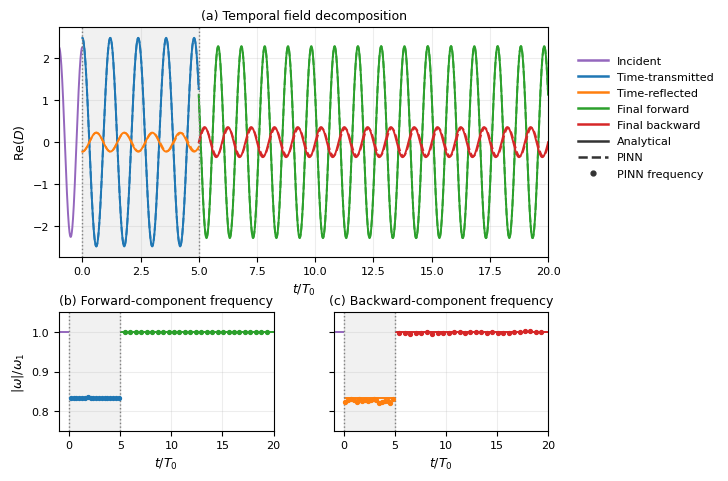

Saved: /content/drive/MyDrive/TimeVaryingMedia/temporal_slab_wave_splitting_20260831_1226/figures/figure5_temporal_slab_frequency.pdf
Saved: /content/drive/MyDrive/TimeVaryingMedia/temporal_slab_wave_splitting_20260831_1226/figures/figure5_temporal_slab_frequency.png


In [ ]:
# ============================================================
# Figure 5 — temporal slab:
# (a) temporal field decomposition
# (b) forward-component frequency
# (c) backward-component frequency
#
# Shaded region: temporal slab, 0 <= t < T_slab
#
# Field panel:
#   color  = physical component
#   solid  = Analytical
#   dashed = PINN
#
# Frequency panels:
#   solid line = Analytical/reference
#   dots       = PINN extracted
# ============================================================

from matplotlib.lines import Line2D

plt.rcParams.update({
    "font.size": 8,
    "axes.labelsize": 9,
    "axes.titlesize": 9,
    "legend.fontsize": 8,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "lines.linewidth": 1.4,
})


# ============================================================
# Figure layout
# Leave space on the right for one vertical legend
# ============================================================

fig = plt.figure(
    figsize=(7.3, 4.8)
)

gs = fig.add_gridspec(
    2, 2,
    height_ratios=[1.65, 0.85],
    hspace=0.32,
    wspace=0.28,
)

ax_field = fig.add_subplot(
    gs[0, :]
)

ax_freq_fwd = fig.add_subplot(
    gs[1, 0]
)

ax_freq_bwd = fig.add_subplot(
    gs[1, 1],
    sharey=ax_freq_fwd,
)


# ============================================================
# Common colors
# ============================================================

c_inc = "tab:purple"
c_tr  = "tab:blue"
c_ref = "tab:orange"
c_fwd = "tab:green"
c_bwd = "tab:red"


# ============================================================
# Shade temporal slab
# ============================================================

for ax in [
    ax_field,
    ax_freq_fwd,
    ax_freq_bwd,
]:

    ax.axvspan(
        0.0,
        T_SLAB,
        color="0.85",
        alpha=0.35,
        zorder=0,
    )


# ============================================================
# (a) Temporal field decomposition
# ============================================================

# Incident field before t = 0
ax_field.plot(
    tau_pre,
    np.real(D_pre),
    color=c_inc,
    linestyle="-",
)


# ------------------------------------------------------------
# Inside slab: time-transmitted
# ------------------------------------------------------------

ax_field.plot(
    tau[inside],
    np.real(D_plus_exact[inside]),
    color=c_tr,
    linestyle="-",
)

ax_field.plot(
    tau[inside],
    np.real(D_plus[inside]),
    color=c_tr,
    linestyle="--",
)


# ------------------------------------------------------------
# Inside slab: time-reflected
# ------------------------------------------------------------

ax_field.plot(
    tau[inside],
    np.real(D_minus_exact[inside]),
    color=c_ref,
    linestyle="-",
)

ax_field.plot(
    tau[inside],
    np.real(D_minus[inside]),
    color=c_ref,
    linestyle="--",
)


# ------------------------------------------------------------
# After slab: final forward
# ------------------------------------------------------------

ax_field.plot(
    tau[after],
    np.real(D_plus_exact[after]),
    color=c_fwd,
    linestyle="-",
)

ax_field.plot(
    tau[after],
    np.real(D_plus[after]),
    color=c_fwd,
    linestyle="--",
)


# ------------------------------------------------------------
# After slab: final backward
# ------------------------------------------------------------

ax_field.plot(
    tau[after],
    np.real(D_minus_exact[after]),
    color=c_bwd,
    linestyle="-",
)

ax_field.plot(
    tau[after],
    np.real(D_minus[after]),
    color=c_bwd,
    linestyle="--",
)


ax_field.set_ylabel(
    r"Re$(D)$"
)

ax_field.set_xlabel(
    r"$t/T_0$"
)

ax_field.set_title(
    "(a) Temporal field decomposition"
)

ax_field.grid(
    True,
    alpha=0.22,
)


# ============================================================
# Frequency-marker indices
# Avoid temporal-interface neighborhoods
# ============================================================

idx_inside = np.where(inside)[0]
idx_after  = np.where(after)[0]

trim_inside = max(
    1,
    int(0.03 * len(idx_inside))
)

trim_after = max(
    1,
    int(0.03 * len(idx_after))
)

marker_step_inside = max(
    1,
    len(idx_inside) // 18
)

marker_step_after = max(
    1,
    len(idx_after) // 28
)

idx_inside_plot = idx_inside[
    trim_inside:-trim_inside:marker_step_inside
]

idx_after_plot = idx_after[
    trim_after:-trim_after:marker_step_after
]


# ============================================================
# (b) Forward-component frequency
# ============================================================

# Incident reference
ax_freq_fwd.hlines(
    1.0,
    -PRE_TAU,
    0.0,
    color=c_inc,
    linestyle="-",
    linewidth=1.4,
)


# ------------------------------------------------------------
# Time-transmitted frequency
# ------------------------------------------------------------

# Analytical/reference
ax_freq_fwd.hlines(
    omega2_norm,
    0.0,
    T_SLAB,
    color=c_tr,
    linestyle="-",
    linewidth=1.4,
)

# PINN extracted
ax_freq_fwd.plot(
    tau[idx_inside_plot],
    np.abs(
        omega_plus_pinn[
            idx_inside_plot
        ]
    ),
    linestyle="none",
    marker="o",
    markersize=2.8,
    color=c_tr,
    zorder=5,
)


# ------------------------------------------------------------
# Final-forward frequency
# ------------------------------------------------------------

# Analytical/reference
ax_freq_fwd.hlines(
    1.0,
    T_SLAB,
    TAU_MAX,
    color=c_fwd,
    linestyle="-",
    linewidth=1.4,
)

# PINN extracted
ax_freq_fwd.plot(
    tau[idx_after_plot],
    np.abs(
        omega_plus_pinn[
            idx_after_plot
        ]
    ),
    linestyle="none",
    marker="o",
    markersize=2.8,
    color=c_fwd,
    zorder=5,
)


ax_freq_fwd.set_title(
    "(b) Forward-component frequency"
)

ax_freq_fwd.set_ylabel(
    r"$|\omega|/\omega_1$"
)

ax_freq_fwd.set_xlabel(
    r"$t/T_0$"
)

ax_freq_fwd.grid(
    True,
    alpha=0.22,
)


# ============================================================
# (c) Backward-component frequency
# ============================================================

# Incident reference shown only for temporal context
ax_freq_bwd.hlines(
    1.0,
    -PRE_TAU,
    0.0,
    color=c_inc,
    linestyle="-",
    linewidth=1.4,
)


# ------------------------------------------------------------
# Time-reflected frequency
# ------------------------------------------------------------

# Analytical/reference
ax_freq_bwd.hlines(
    omega2_norm,
    0.0,
    T_SLAB,
    color=c_ref,
    linestyle="-",
    linewidth=1.4,
)

# PINN extracted
ax_freq_bwd.plot(
    tau[idx_inside_plot],
    np.abs(
        omega_minus_pinn[
            idx_inside_plot
        ]
    ),
    linestyle="none",
    marker="o",
    markersize=2.8,
    color=c_ref,
    zorder=5,
)


# ------------------------------------------------------------
# Final-backward frequency
# ------------------------------------------------------------

# Analytical/reference
ax_freq_bwd.hlines(
    1.0,
    T_SLAB,
    TAU_MAX,
    color=c_bwd,
    linestyle="-",
    linewidth=1.4,
)

# PINN extracted
ax_freq_bwd.plot(
    tau[idx_after_plot],
    np.abs(
        omega_minus_pinn[
            idx_after_plot
        ]
    ),
    linestyle="none",
    marker="o",
    markersize=2.8,
    color=c_bwd,
    zorder=5,
)


ax_freq_bwd.set_title(
    "(c) Backward-component frequency"
)

ax_freq_bwd.set_xlabel(
    r"$t/T_0$"
)

ax_freq_bwd.grid(
    True,
    alpha=0.22,
)


# ============================================================
# Common frequency-panel formatting
# ============================================================

for ax in [
    ax_freq_fwd,
    ax_freq_bwd,
]:

    ax.set_ylim(
        0.75,
        1.05,
    )

    ax.set_yticks([
        0.8,
        0.9,
        1.0,
    ])


# Same y-scale; y labels only on the left panel
plt.setp(
    ax_freq_bwd.get_yticklabels(),
    visible=False,
)


# ============================================================
# Temporal interfaces
# ============================================================

for ax in [
    ax_field,
    ax_freq_fwd,
    ax_freq_bwd,
]:

    ax.axvline(
        0.0,
        color="0.5",
        linestyle=":",
        linewidth=1.0,
    )

    ax.axvline(
        T_SLAB,
        color="0.5",
        linestyle=":",
        linewidth=1.0,
    )

    ax.set_xlim(
        -PRE_TAU,
        TAU_MAX,
    )


# ============================================================
# One vertical legend outside the plots
# ============================================================

legend_handles = [

    # --------------------------------------------------------
    # Physical components
    # --------------------------------------------------------

    Line2D(
        [0], [0],
        color=c_inc,
        lw=1.8,
        linestyle="-",
        label="Incident",
    ),

    Line2D(
        [0], [0],
        color=c_tr,
        lw=1.8,
        linestyle="-",
        label="Time-transmitted",
    ),

    Line2D(
        [0], [0],
        color=c_ref,
        lw=1.8,
        linestyle="-",
        label="Time-reflected",
    ),

    Line2D(
        [0], [0],
        color=c_fwd,
        lw=1.8,
        linestyle="-",
        label="Final forward",
    ),

    Line2D(
        [0], [0],
        color=c_bwd,
        lw=1.8,
        linestyle="-",
        label="Final backward",
    ),


    # --------------------------------------------------------
    # Field-solution convention
    # --------------------------------------------------------

    Line2D(
        [0], [0],
        color="0.20",
        lw=1.8,
        linestyle="-",
        label="Analytical",
    ),

    Line2D(
        [0], [0],
        color="0.20",
        lw=1.8,
        linestyle="--",
        label="PINN",
    ),


    # --------------------------------------------------------
    # Frequency-extraction convention
    # --------------------------------------------------------

    Line2D(
        [0], [0],
        color="0.20",
        marker="o",
        linestyle="none",
        markersize=3.5,
        label="PINN frequency",
    ),
]


# Figure-level legend:
# outside the plotting area, vertical column
fig.legend(
    handles=legend_handles,
    frameon=False,
    ncol=1,
    loc="upper left",
    bbox_to_anchor=(0.805, 0.90),
    borderaxespad=0.0,
    handlelength=2.7,
    labelspacing=0.55,
)


# ============================================================
# Layout
#
# Reserve ~22% of the figure width for the outside legend
# ============================================================

fig.subplots_adjust(
    left=0.10,
    right=0.77,
    bottom=0.11,
    top=0.95,
    hspace=0.32,
    wspace=0.28,
)


# ============================================================
# Save
# ============================================================

fig.savefig(
    FIGURES_DIR
    / "figure5_temporal_slab_frequency.pdf",
    bbox_inches="tight",
)

fig.savefig(
    FIGURES_DIR
    / "figure5_temporal_slab_frequency.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

print(
    "Saved:",
    FIGURES_DIR
    / "figure5_temporal_slab_frequency.pdf",
)

print(
    "Saved:",
    FIGURES_DIR
    / "figure5_temporal_slab_frequency.png",
)


## Saved results

The output directory contains the complete configuration, trained model,
run-level metrics, loss history, analytical and PINN fields, decomposed
temporal components, and Figure 5 in PDF and PNG formats.
